# State Estimation Techniques: Polarimetry and Malus' Law

**Course:** Control and Planning (CAPN), Semester 6, Plaksha University

## Objective
**Estimate the optical rotation angle (θ_min) accurately from noisy intensity measurements using different estimation techniques.**

## Data Description
The dataset consists of multiple CSV files containing:
- **Angle (θ)**: Analyzer angle in degrees
- **Intensity (I)**: Measured light intensity at that angle

For each sucrose concentration level:
- 3 trials are recorded
- Each trial contains 5 repeated measurements
- Data is organized into:
  - **Raw intensity values**
  - **Normalized intensity values** (scaled to remove amplitude variations)

To improve reliability:
- Measurements are **grouped by concentration**
- **Averaging** is performed across trials
- **Standard deviation** is used to visualize measurement noise

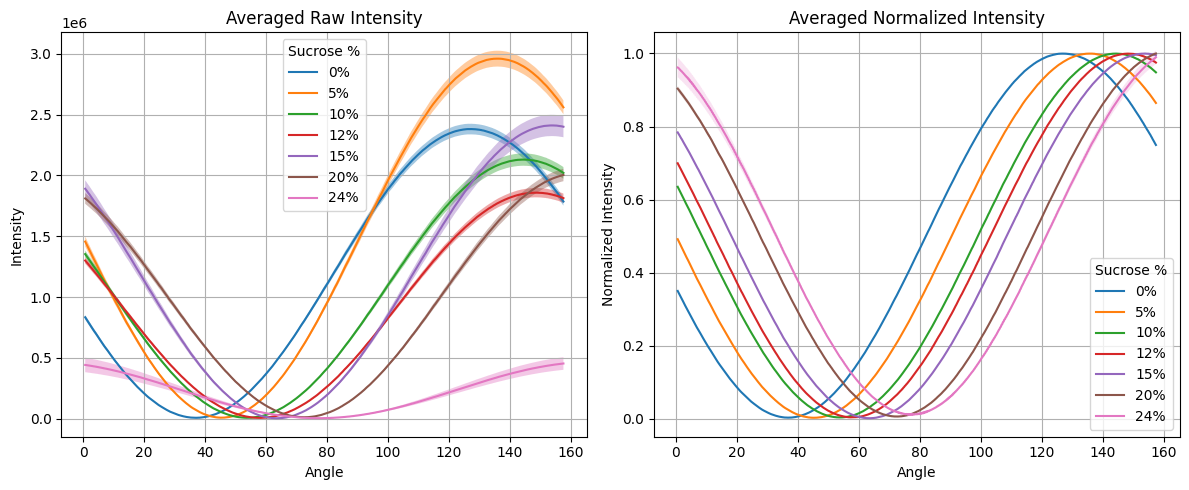

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PART 1: DATA LOADING AND PREPROCESSING
# ------------------------------------------------------------
# - Loads polarimeter datasets for multiple sucrose levels
# - Organizes raw and normalized intensity data
# - Each dataset contains angle vs intensity measurements
# ============================================================

base_path = os.path.join("data", "angle_intensity_0-24")
np.random.seed(26)   # makes the particle filter reproducible

# Sucrose concentration levels (%)
sucrose_levels = [0, 5, 10, 12, 15, 20, 24]
trials = [1, 2, 3]

# Dictionaries to store grouped datasets
grouped_raw = {s: [] for s in sucrose_levels}
grouped_norm = {s: [] for s in sucrose_levels}

# ------------------------------------------------------------
# Load all CSV files and organize into structured format
# ------------------------------------------------------------
for sucrose in sucrose_levels:
    for t in trials:
        filename = f"angle_intensity_{sucrose}_{t}.csv"
        filepath = os.path.join(base_path, filename)

        df = pd.read_csv(filepath)

        # Extract test numbers dynamically
        test_numbers = sorted(set(
            col.split("_")[0] for col in df.columns if "Angle" in col
        ))

        for test in test_numbers:
            angle_col = f"{test}_Angle"
            intensity_col = f"{test}_Intensity"

            if angle_col in df.columns and intensity_col in df.columns:

                temp_df = df[[angle_col, intensity_col]].dropna()
                temp_df.columns = ["angle", "intensity"]

                # RAW
                grouped_raw[sucrose].append(temp_df)

                # NORMALIZED
                norm_df = temp_df.copy()
                norm_df["intensity"] = norm_df["intensity"] / norm_df["intensity"].max()
                grouped_norm[sucrose].append(norm_df)

# ============================================================
# FUNCTION: AVERAGE MULTIPLE TRIALS
# ------------------------------------------------------------
# - Computes mean and standard deviation across trials
# - Used for noise reduction and smoother visualization
# ============================================================

def average_curves(datasets):
    """
    Takes list of dataframes and returns averaged curve
    Assumes same angle sampling
    """
    angles = datasets[0]["angle"].values
    
    intensities = np.array([
        df["intensity"].values for df in datasets
    ])
    
    mean_intensity = np.mean(intensities, axis=0)
    std_intensity = np.std(intensities, axis=0)

    return angles, mean_intensity, std_intensity

# ============================================================
# VISUALIZATION: RAW VS NORMALIZED DATA
# ------------------------------------------------------------
# - Helps identify minima visually
# - Shows noise using standard deviation bands
# ============================================================

plt.figure(figsize=(12, 5))

# -------- RAW --------
plt.subplot(1, 2, 1)

for sucrose in sucrose_levels:
    angles, mean_I, std_I = average_curves(grouped_raw[sucrose])
    
    plt.plot(angles, mean_I, label=f"{sucrose}%")
    plt.fill_between(angles, mean_I - std_I, mean_I + std_I, alpha=0.4)

plt.title("Averaged Raw Intensity")
plt.xlabel("Angle")
plt.ylabel("Intensity")
plt.legend(title="Sucrose %")
plt.grid()

# -------- NORMALIZED --------
plt.subplot(1, 2, 2)

for sucrose in sucrose_levels:
    angles, mean_I, std_I = average_curves(grouped_norm[sucrose])
    
    plt.plot(angles, mean_I, label=f"{sucrose}%")
    plt.fill_between(angles, mean_I - std_I, mean_I + std_I, alpha=0.2)

plt.title("Averaged Normalized Intensity")
plt.xlabel("Angle")
plt.ylabel("Normalized Intensity")
plt.legend(title="Sucrose %")
plt.grid()

plt.tight_layout()
plt.show()

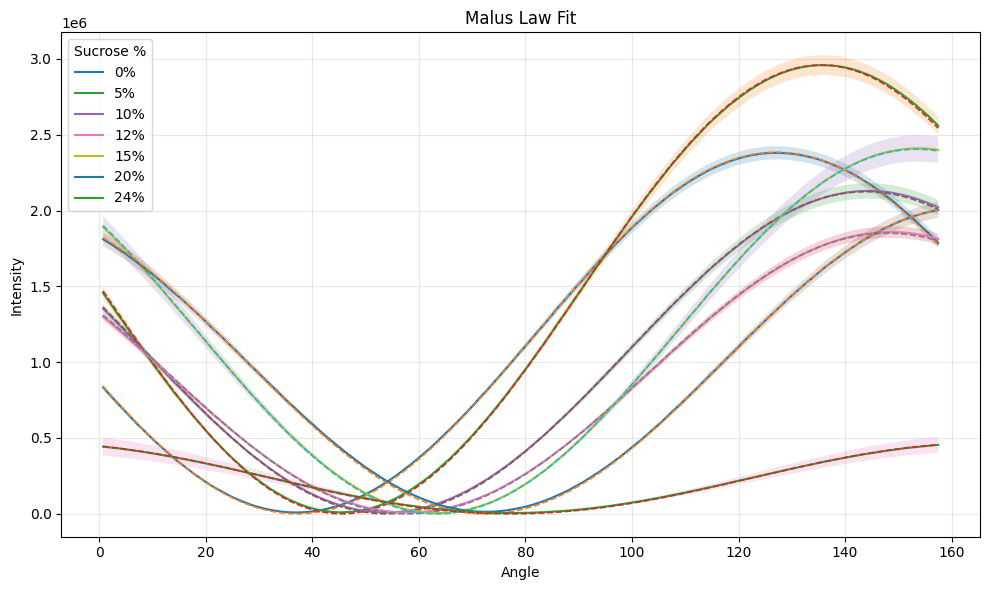


Estimated Theta_min:
0% → θ_min = 37.09 degrees
5% → θ_min = 45.48 degrees
10% → θ_min = 53.92 degrees
12% → θ_min = 57.94 degrees
15% → θ_min = 63.44 degrees
20% → θ_min = 72.44 degrees
24% → θ_min = 77.28 degrees


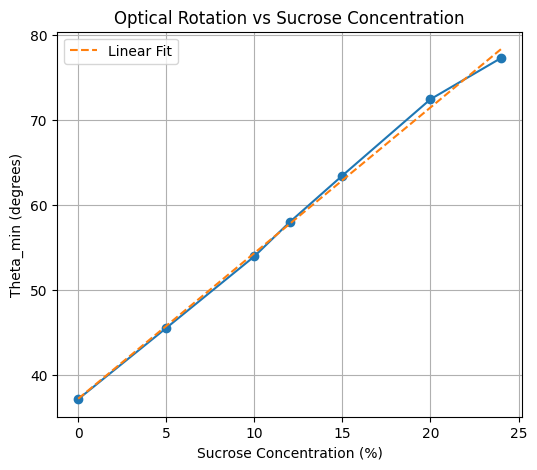


Linear relationship: θ_min = 1.716 * concentration + 37.142


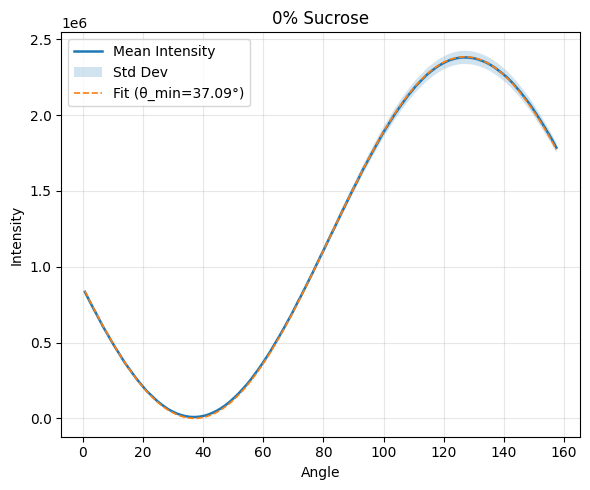

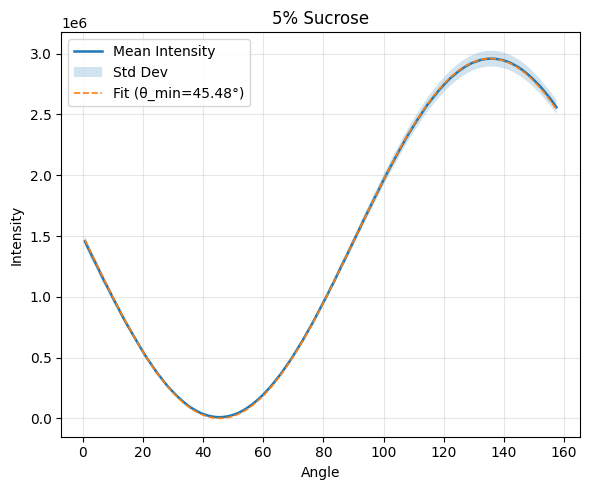

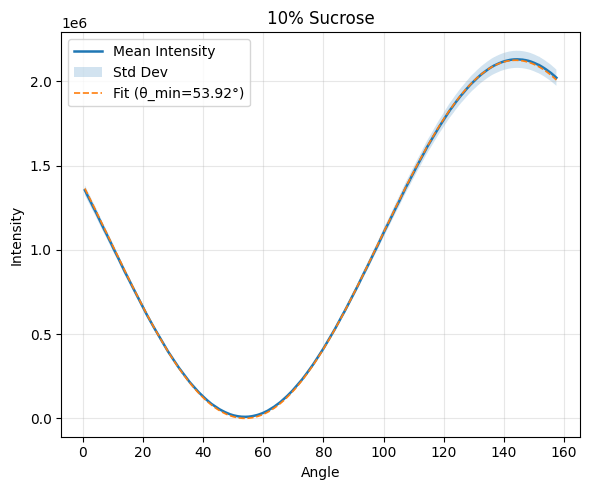

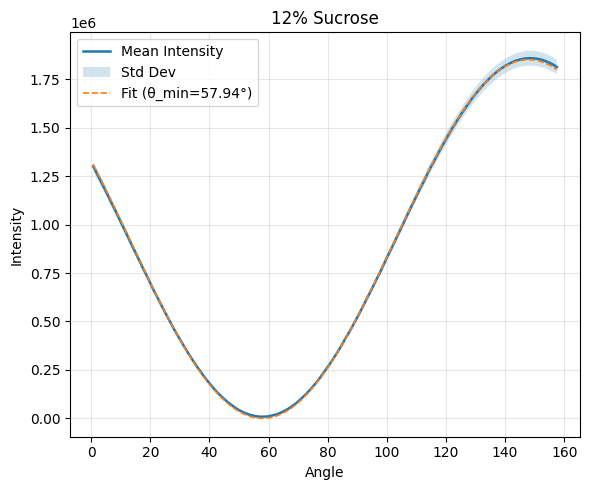

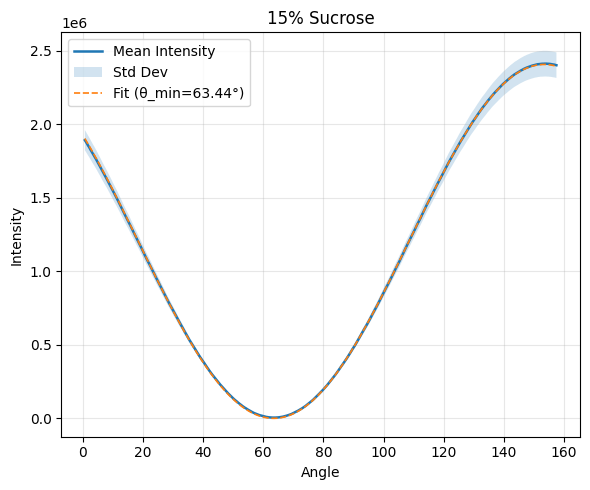

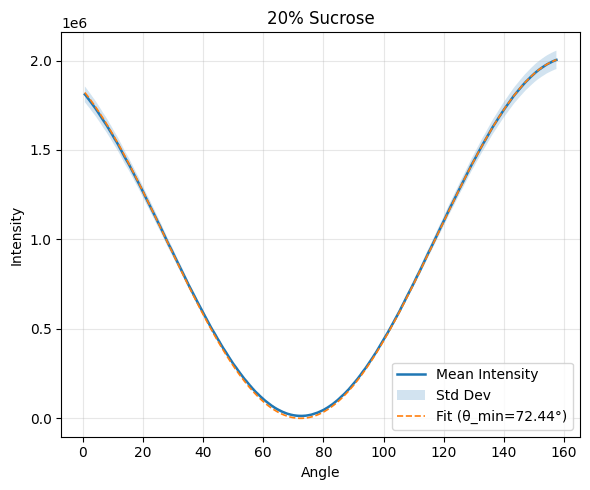

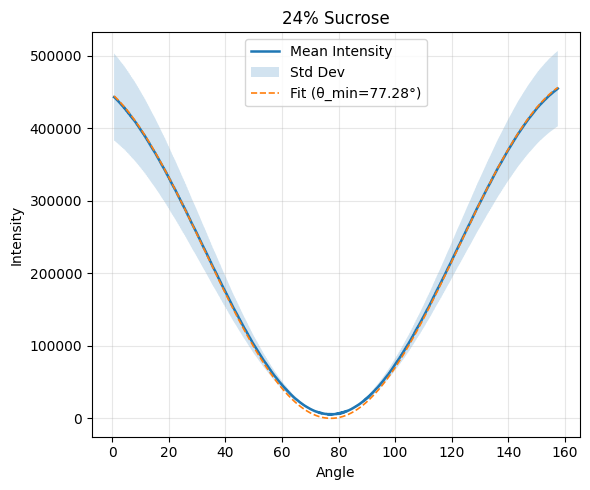

In [2]:
from scipy.optimize import curve_fit

# ============================================================
# PART 1: MALUS LAW MODEL FITTING
# ------------------------------------------------------------
# - Fits nonlinear Malus Law to experimental data
# - Estimates theta_min (optical rotation angle)
# ============================================================

def malus_law(theta, I0, theta_min):
    return I0 * (np.sin(np.radians(theta - theta_min)) ** 2)

# ============================================================
# NONLINEAR CURVE FITTING
# ------------------------------------------------------------
# - Fits model to averaged data
# - Extracts theta_min for each sucrose level
# ============================================================

plt.figure(figsize=(10, 6))

theta_min_results = {}

for sucrose in sucrose_levels:
    
    angles, mean_I, std_I = average_curves(grouped_raw[sucrose])

    I0_guess = np.max(mean_I)
    theta_guess = angles[np.argmin(mean_I)]

    try:
        popt, _ = curve_fit(
            malus_law,
            angles,
            mean_I,
            p0=[I0_guess, theta_guess],
            bounds=([0, 0], [np.inf, 180])
        )

        I0_fit, theta_min_fit = popt
        theta_min_results[sucrose] = theta_min_fit

        # Smooth curve
        theta_smooth = np.linspace(min(angles), max(angles), 300)

        # Plot mean curve 
        plt.plot(angles, mean_I, linewidth=1.5, label=f"{sucrose}%")

        # Shaded std band
        plt.fill_between(
            angles,
            mean_I - std_I,
            mean_I + std_I,
            alpha=0.2
        )

        # Fit curve (thin dashed)
        plt.plot(
            theta_smooth,
            malus_law(theta_smooth, I0_fit, theta_min_fit),
            linestyle='--',
            linewidth=1.2
        )

    except RuntimeError:
        print(f"Fit failed for {sucrose}%")

plt.xlabel("Angle")
plt.ylabel("Intensity")
plt.title("Malus Law Fit")
plt.legend(title="Sucrose %")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# RESULTS: THETA_MIN VALUES
# ============================================================

print("\nEstimated Theta_min:")
for sucrose, theta_val in theta_min_results.items():
    print(f"{sucrose}% → θ_min = {theta_val:.2f} degrees")
    
# =========================
# THETA_MIN vs SUCROSE
# =========================

sucrose_vals = sorted(theta_min_results.keys())
theta_vals = [theta_min_results[s] for s in sucrose_vals]

plt.figure(figsize=(6, 5))
plt.plot(sucrose_vals, theta_vals, marker='o')
plt.xlabel("Sucrose Concentration (%)")
plt.ylabel("Theta_min (degrees)")
plt.title("Optical Rotation vs Sucrose Concentration")
plt.grid()

# Optional: linear fit
coeffs = np.polyfit(sucrose_vals, theta_vals, 1)
fit_line = np.poly1d(coeffs)

x_fit = np.linspace(min(sucrose_vals), max(sucrose_vals), 100)
plt.plot(x_fit, fit_line(x_fit), linestyle='--', label="Linear Fit")

plt.legend()
plt.show()

print(f"\nLinear relationship: θ_min = {coeffs[0]:.3f} * concentration + {coeffs[1]:.3f}")

# =========================
# INDIVIDUAL PLOTS
# =========================

for sucrose in sucrose_levels:

    angles, mean_I, std_I = average_curves(grouped_raw[sucrose])

    plt.figure(figsize=(6, 5))

    try:
        popt, _ = curve_fit(
            malus_law,
            angles,
            mean_I,
            p0=[np.max(mean_I), angles[np.argmin(mean_I)]],
            bounds=([0, 0], [np.inf, 180])
        )

        I0_fit, theta_min_fit = popt

        theta_smooth = np.linspace(min(angles), max(angles), 300)

        # Mean curve
        plt.plot(
            angles,
            mean_I,
            linewidth=1.8,
            label="Mean Intensity"
        )

        # Shaded noise band
        plt.fill_between(
            angles,
            mean_I - std_I,
            mean_I + std_I,
            alpha=0.2,
            label="Std Dev"
        )

        # Fit curve
        plt.plot(
            theta_smooth,
            malus_law(theta_smooth, I0_fit, theta_min_fit),
            linestyle='--',
            linewidth=1.2,
            label=f"Fit (θ_min={theta_min_fit:.2f}°)"
        )

    except RuntimeError:
        plt.plot(angles, mean_I, linewidth=1.5, label="Data (fit failed)")

    plt.xlabel("Angle")
    plt.ylabel("Intensity")
    plt.title(f"{sucrose}% Sucrose")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## Part 1: Data Exploration and Problem Formulation

---

### Visual Inspection of Intensity Curves
Plotting intensity versus angle reveals a characteristic periodic curve. 

From the plots:
- The minima shifts with sucrose concentration  
- Noise appears as fluctuations around the smooth curve  
- Standard deviation bands highlight uncertainty in measurements  
- 24% sucrose concrentration is seen to have highest variance in data, with other concrentration having similar variations 

---

### Relation to Malus' Law
The observed data follows the theoretical model given by:

I(θ) = I₀ sin²(θ − θ_min)

where:
- *I₀* is the maximum intensity  
- *θ_min* represents the angle of minimum intensity  

To obtain a precise estimate of θ_min:
- A **nonlinear curve fitting** approach is used  
- The model is fitted to averaged intensity data  
- θ_min is extracted as a model parameter  

This approach is more robust than visual estimation and accounts for noise in the measurements.

#### sine-square instead of cos-square
Malus' Law is written as:

I(θ) = I₀ cos²(θ − θ₀)

using this formula I got the maxima instead.

However, in this experiment we are interested in the **angle of minimum intensity (θ_min)**.  
Using the trigonometric identity:

cos²(x) = sin²(x + 90°)

we can rewrite the model as:

I(θ) = I₀ sin²(θ − θ_min)

where:
- θ_min = θ₀ − 90°
---

### Observed Deviations from Theory
Although the overall trend matches Malus' Law, some deviations are observed:
- Slight asymmetry in curves  
- Irregular fluctuations around the fitted model  
- Variation in peak and minimum sharpness  

These deviations indicate the presence of noise and imperfections in the measurement system.

---

### Sources of Measurement Noise
Several factors contribute to inaccuracies in estimating θ_min:

**Sensor Noise**
- Limited resolution of photodetectors  
- Electronic noise in measurement circuits  

**Mechanical Errors**
- Imperfect rotation of the analyzer  
- Misalignment of optical components  

**Environmental Factors**
- Temperature variations affecting optical properties  
- Ambient light interference  

**Source Instability**
- Fluctuations in light source intensity over time  

**Sampling Errors**
- Limited sampling resolution near the minimum  

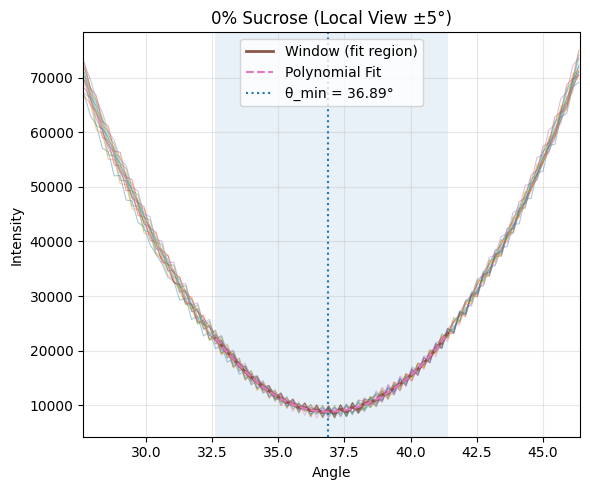

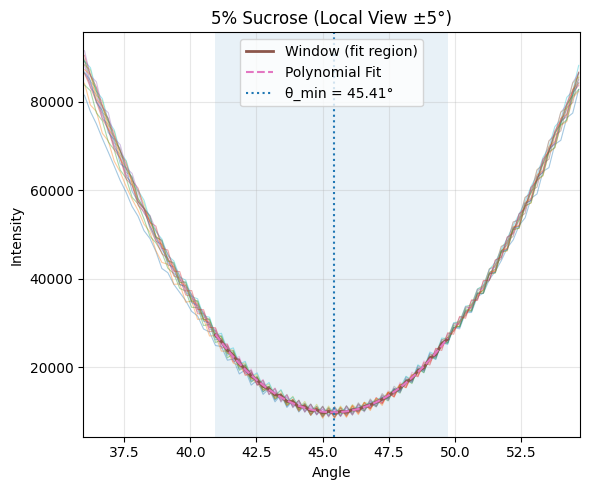

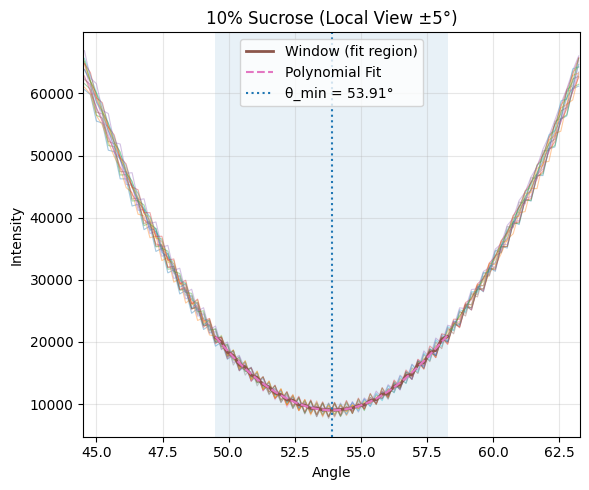

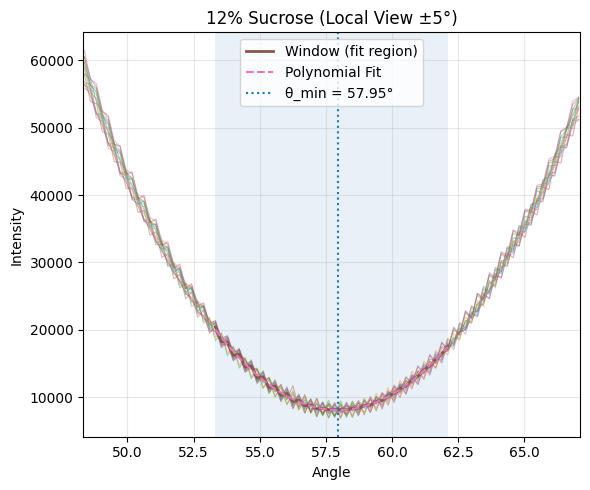

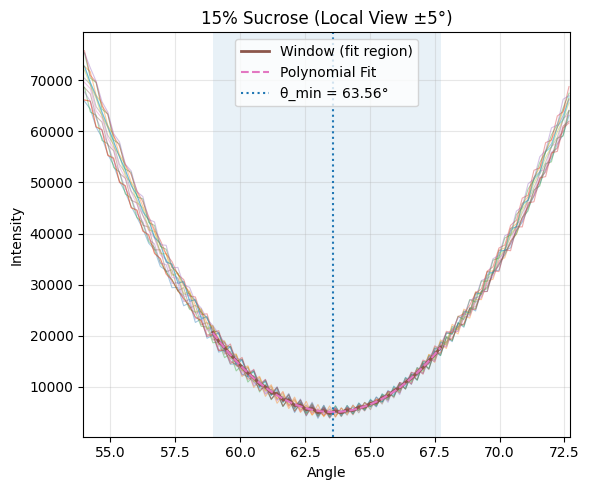

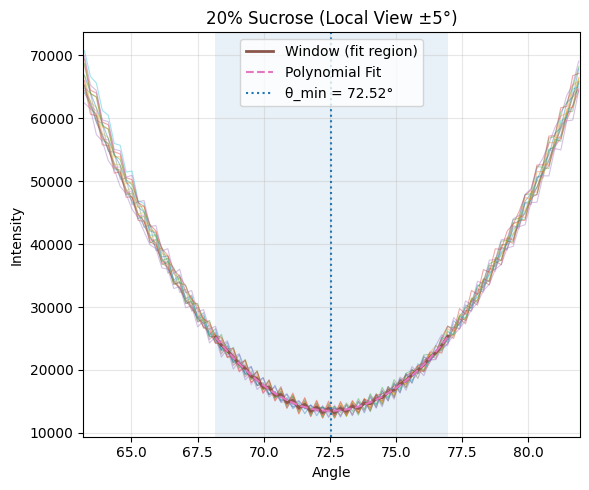

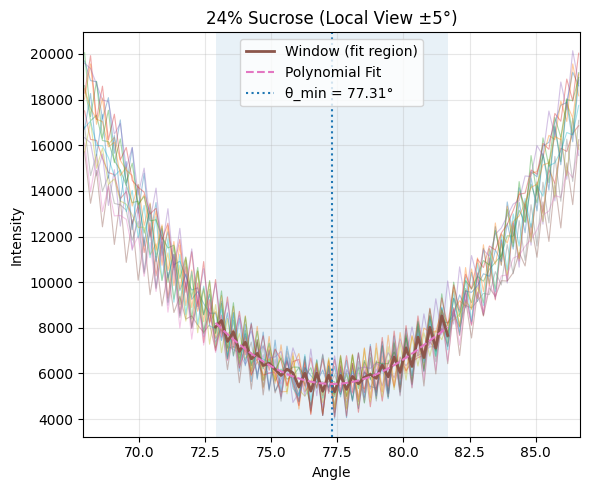


Polynomial Estimated Theta_min:
0% → θ_min = 36.89 degrees
5% → θ_min = 45.41 degrees
10% → θ_min = 53.91 degrees
12% → θ_min = 57.95 degrees
15% → θ_min = 63.56 degrees
20% → θ_min = 72.52 degrees
24% → θ_min = 77.31 degrees


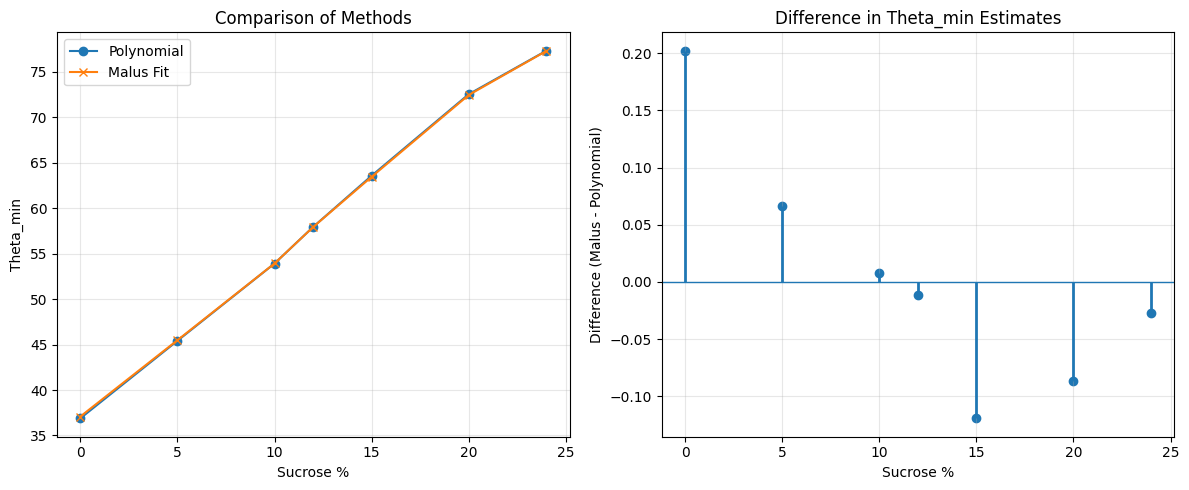

Difference (Malus - Polynomial):
0% → Δθ = 0.20219 degrees
5% → Δθ = 0.06636 degrees
10% → Δθ = 0.00822 degrees
12% → Δθ = -0.01118 degrees
15% → Δθ = -0.11921 degrees
20% → Δθ = -0.08645 degrees
24% → Δθ = -0.02703 degrees


In [3]:
# ============================================================
# PART 2.1: NON-RECURSIVE METHOD (POLYNOMIAL FIT)
# ------------------------------------------------------------
# - Selects local region near minimum
# - Fits 5th-order polynomial
# - Estimates theta_min from smoothed curve
# ============================================================

def get_local_region(angles, intensity, window=20):
    """
    Selects a window around the rough minimum
    """
    idx_min = np.argmin(intensity)
    
    lower = max(0, idx_min - window)
    upper = min(len(angles), idx_min + window)
    
    return angles[lower:upper], intensity[lower:upper]

def poly_fit_minimum(angles, intensity, degree=5):
    """
    Polynomial smoothing and minimum estimation
    """
    coeffs = np.polyfit(angles, intensity, degree)
    poly = np.poly1d(coeffs)
    
    theta_dense = np.linspace(min(angles), max(angles), 1000)
    intensity_dense = poly(theta_dense)
    
    theta_min = theta_dense[np.argmin(intensity_dense)]
    
    return theta_min, theta_dense, intensity_dense

theta_poly_results = {}

for sucrose in sucrose_levels:

    plt.figure(figsize=(6,5))

    datasets = grouped_raw[sucrose]

    # Average curve for window detection
    angles_avg, mean_I, _ = average_curves(datasets)

    # Get local region
    ang_local, I_local = get_local_region(angles_avg, mean_I)

    # Define plotting range (window ± 5°)
    plot_min = min(ang_local) - 5
    plot_max = max(ang_local) + 5

    # Polynomial fit
    theta_min_poly, theta_dense, I_dense = poly_fit_minimum(ang_local, I_local)
    theta_poly_results[sucrose] = theta_min_poly

    for df in datasets:
        mask = (df["angle"] >= plot_min) & (df["angle"] <= plot_max)

        plt.plot(
            df["angle"][mask],
            df["intensity"][mask],
            linewidth=0.8,
            alpha=0.4
        )

    plt.plot(
        ang_local,
        I_local,
        linewidth=2,
        label="Window (fit region)"
    )

    mask_fit = (theta_dense >= plot_min) & (theta_dense <= plot_max)

    plt.plot(
        theta_dense[mask_fit],
        I_dense[mask_fit],
        linestyle='--',
        linewidth=1.5,
        label="Polynomial Fit"
    )

    plt.axvline(
        theta_min_poly,
        linestyle=':',
        linewidth=1.5,
        label=f"θ_min = {theta_min_poly:.2f}°"
    )

    plt.axvspan(
        min(ang_local),
        max(ang_local),
        alpha=0.1
    )

    plt.xlim(plot_min, plot_max)

    # Labels
    plt.xlabel("Angle")
    plt.ylabel("Intensity")
    plt.title(f"{sucrose}% Sucrose (Local View ±5°)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.show()

print("\nPolynomial Estimated Theta_min:")
for s, val in theta_poly_results.items():
    print(f"{s}% → θ_min = {val:.2f} degrees")
    
sucrose_vals = sorted(theta_poly_results.keys())

poly_vals = np.array([theta_poly_results[s] for s in sucrose_vals])
malus_vals = np.array([theta_min_results[s] for s in sucrose_vals])

diff = malus_vals - poly_vals
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# -------- PLOT 1: COMPARISON --------
axes[0].plot(sucrose_vals, poly_vals, marker='o', linewidth=1.5, label="Polynomial")
axes[0].plot(sucrose_vals, malus_vals, marker='x', linewidth=1.5, label="Malus Fit")

axes[0].set_xlabel("Sucrose %")
axes[0].set_ylabel("Theta_min")
axes[0].set_title("Comparison of Methods")
axes[0].legend()
axes[0].grid(alpha=0.3)

# -------- PLOT 2: DIFFERENCE --------
axes[1].axhline(0, linewidth=1)  # zero reference line

# Vertical lines from 0 to diff
for i, val in enumerate(diff):
    axes[1].vlines(
        x=sucrose_vals[i],
        ymin=0,
        ymax=val,
        linewidth=2
    )

# End markers
axes[1].scatter(sucrose_vals, diff)

axes[1].set_xlabel("Sucrose %")
axes[1].set_ylabel("Difference (Malus - Polynomial)")
axes[1].set_title("Difference in Theta_min Estimates")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Difference (Malus - Polynomial):")
for s in sucrose_vals:
    diff_val = theta_min_results[s] - theta_poly_results[s]
    print(f"{s}% → Δθ = {diff_val:.5f} degrees")

## Part 2.1: Non-Recursive Approach (Polynomial Fitting)

---

#### Local Region Selection
Instead of using the entire dataset, a **subset of data around the minimum intensity region** is selected.

This is done because:
- A small region near the minimum can be well approximated by a polynomial
- Reduces the effect of unrelated fluctuations elsewhere in the data

The minimum index is first identified from averaged data, and a fixed window around it is selected.

---

#### Polynomial Fitting
A **5th-order polynomial** is fitted to the selected local region:

I(θ) ≈ a₀ + a₁θ + a₂θ² + a₃θ³ + a₄θ⁴ + a₅θ⁵

This polynomial acts as a **smooth approximation** of the noisy intensity curve.

---

### Advantages of the Non-Recursive Approach

**Simplicity**
- Easy to implement using standard polynomial fitting tools  
- Does not require system modeling or state-space formulation  

**Noise Reduction**
- Polynomial smoothing reduces high-frequency noise  
- Averaging + fitting improves robustness  

**Deterministic Output**
- Produces a single stable estimate for each dataset  

---

### Limitations

**Local Dependence**
- Accuracy depends on correct selection of the window  
- Poor window choice can bias the estimate  

**Not Real-Time**
- Requires full dataset before processing  
- Cannot update estimates incrementally  

**Model Approximation**
- Polynomial is only an approximation of Malus' Law  
- May introduce slight bias compared to nonlinear fitting  

---

### Comparison with Malus Fit
The polynomial estimate of θ_min is compared with:
- Nonlinear Malus Law fit (ground reference)

The difference:

Δθ = θ_min (Malus) − θ_min (Polynomial)

## Part 2.2: Recursive state estimation

Three recursive estimators process the averaged, normalised curve one angle at a time:

- **Linear Kalman filter.** Malus' law is rewritten as a linear model in the state [a, b, c] (see the docstring), so the filter needs no linearisation.
- **Extended Kalman filter (EKF).** The state is theta_min itself. The measurement sin^2(theta - theta_min) is linearised around the current estimate using its analytical Jacobian. It starts from theta = 30 deg.
- **Particle filter (PF).** 1,000 particles start uniformly on [0, 180) deg, are weighted with a Gaussian likelihood (sigma = 0.05) and resampled after every measurement, with a small 0.05 deg roughening.

In [4]:
# ============================================================
# PART 2.2: RECURSIVE STATE ESTIMATION METHODS
# ------------------------------------------------------------
# - Kalman Filter (KF): linear approximation
# - Extended Kalman Filter (EKF): nonlinear linearization
# - Particle Filter (PF): fully nonlinear, probabilistic
# ============================================================

def kalman_filter(angles, intensities, P0=10.0, q=1e-8, R=0.05**2):
    """
    Linear Kalman filter for theta_min.

    Malus' law with an unknown offset can be written exactly as a linear model:
        I(theta) = I_off + I0 sin^2(theta - theta_min)
                 = a - b cos(2 theta) - c sin(2 theta)
    with a = I_off + I0/2, b = (I0/2) cos(2 theta_min), c = (I0/2) sin(2 theta_min).
    The state x = [a, b, c] is constant, the measurement matrix
    H = [1, -cos 2theta, -sin 2theta] is known at every angle, so a standard
    linear KF applies with no linearisation. theta_min = 0.5 atan2(c, b).

    (My first version linearised sin^2 with a numerical derivative, which made
    it the same filter as the EKF below, hence identical results.)
    """
    x = np.zeros(3)
    P = np.eye(3) * P0
    estimates = []

    for k in range(len(angles)):
        # Prediction: the state is constant, small process noise keeps P from collapsing
        P = P + np.eye(3) * q

        # Update
        th = np.radians(2 * angles[k])
        H = np.array([1.0, -np.cos(th), -np.sin(th)])
        S = H @ P @ H + R
        K = P @ H / S
        x = x + K * (intensities[k] - H @ x)
        P = P - np.outer(K, H) @ P

        estimates.append(np.degrees(0.5 * np.arctan2(x[2], x[1])) % 180)

    return np.array(estimates)

def ekf(angles, intensities, theta_init=30, P=10, Q=0.01, R=0.05):

    x = theta_init
    estimates = []

    for k in range(len(angles)):

        # Prediction
        x_pred = x
        P_pred = P + Q

        # Nonlinear measurement
        z_pred = np.sin(np.radians(angles[k] - x_pred))**2

        # Jacobian (derivative)
        H = -np.sin(2 * np.radians(angles[k] - x_pred)) * np.pi/180

        # Update
        K = P_pred * H / (H * P_pred * H + R)

        x = x_pred + K * (intensities[k] - z_pred)
        P = (1 - K * H) * P_pred

        estimates.append(x)

    return np.array(estimates)

def particle_filter(angles, intensities, N=1000, jitter=0.05):

    particles = np.random.uniform(0, 180, N)
    weights = np.ones(N) / N

    estimates = []

    for k in range(len(angles)):

        # Predict (small noise)
        particles += np.random.normal(0, jitter, N)   # small roughening; 0.5 deg made the cloud drift

        # Compute likelihood
        pred = np.sin(np.radians(angles[k] - particles))**2
        weights *= np.exp(-0.5 * ((intensities[k] - pred)/0.05)**2)

        # Normalize
        weights += 1e-12
        weights /= np.sum(weights)

        # Estimate
        x_est = np.sum(particles * weights)
        estimates.append(x_est)

        # Resample
        indices = np.random.choice(N, size=N, p=weights)
        particles = particles[indices]
        weights = np.ones(N) / N

    return np.array(estimates)

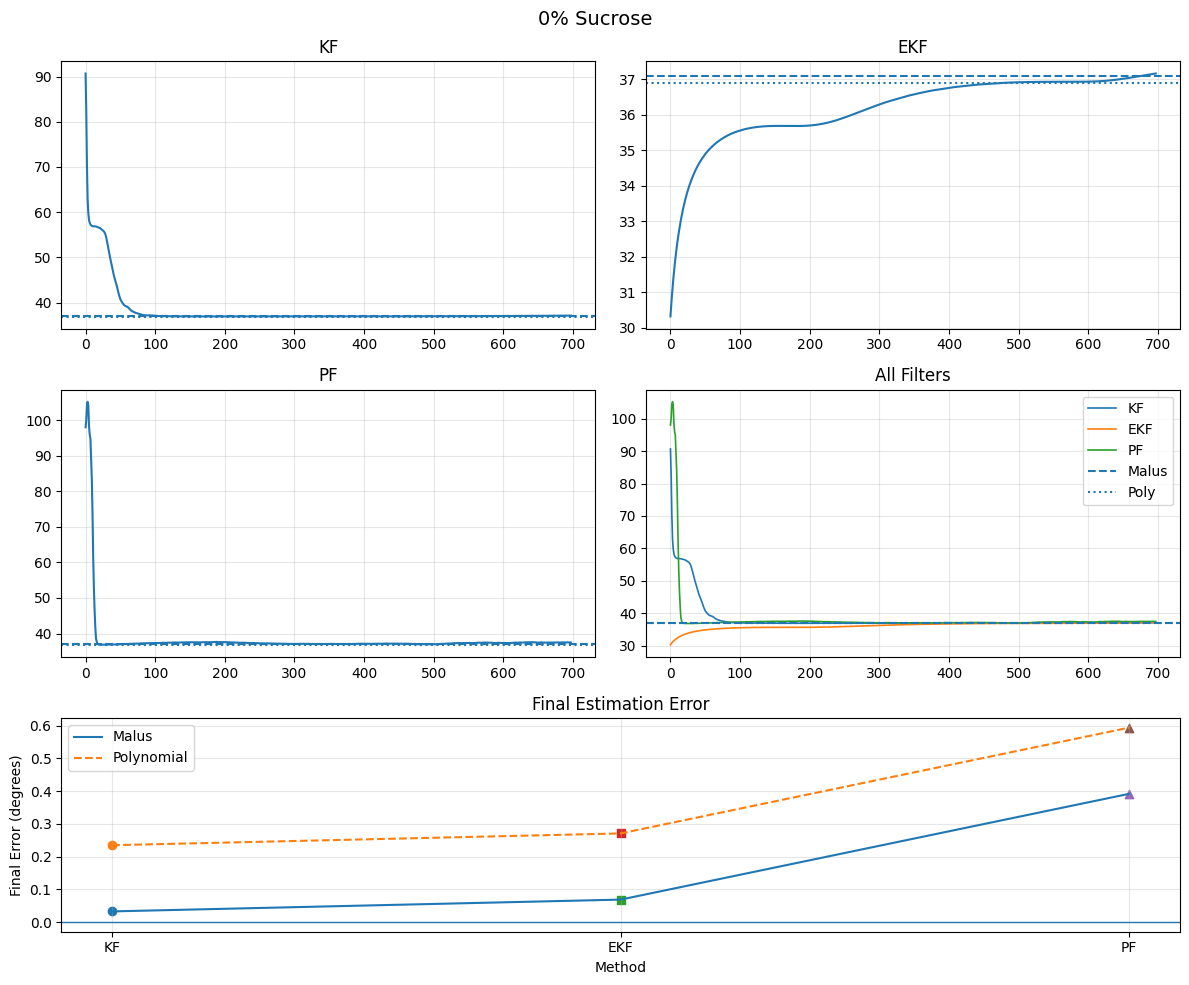

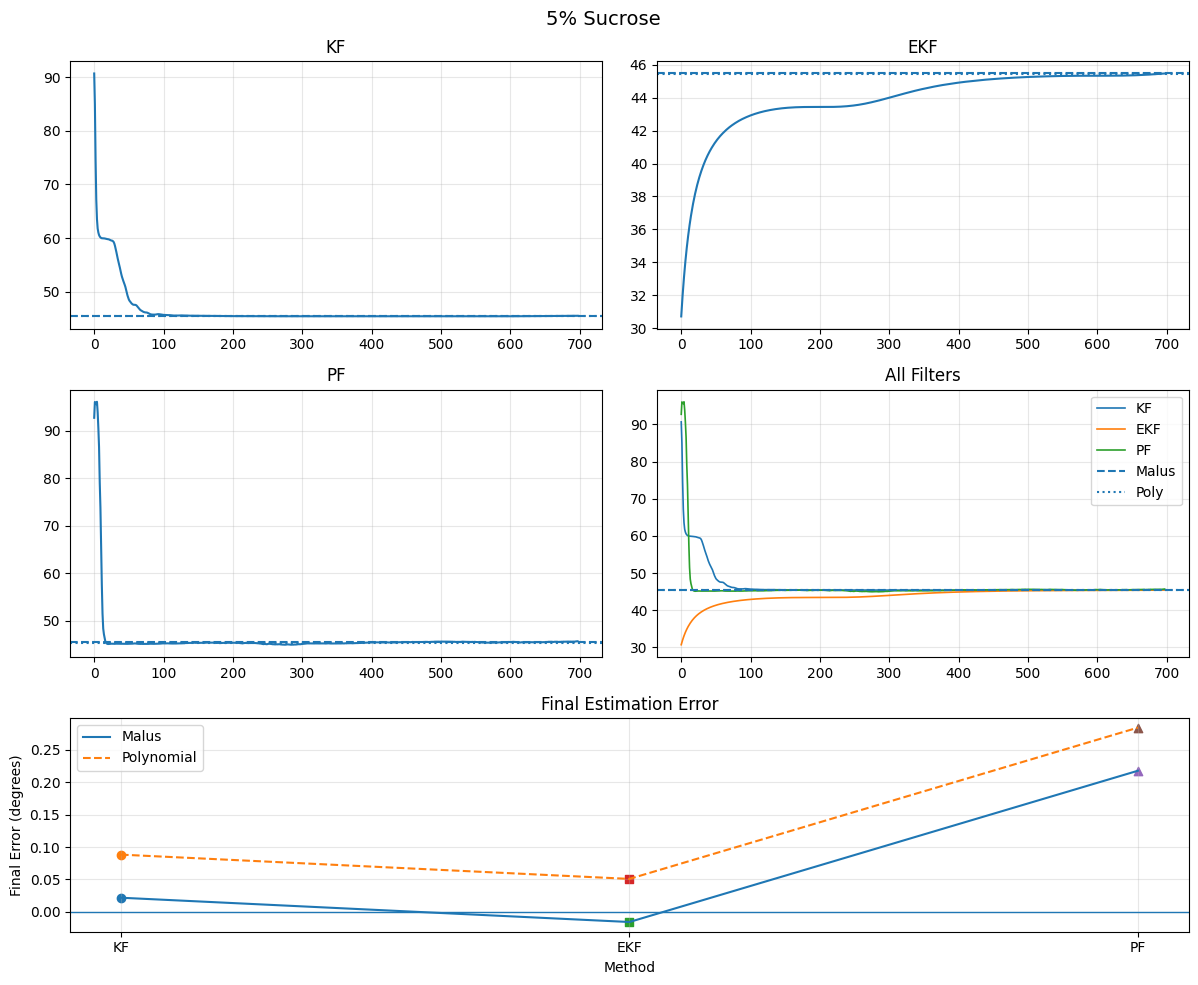

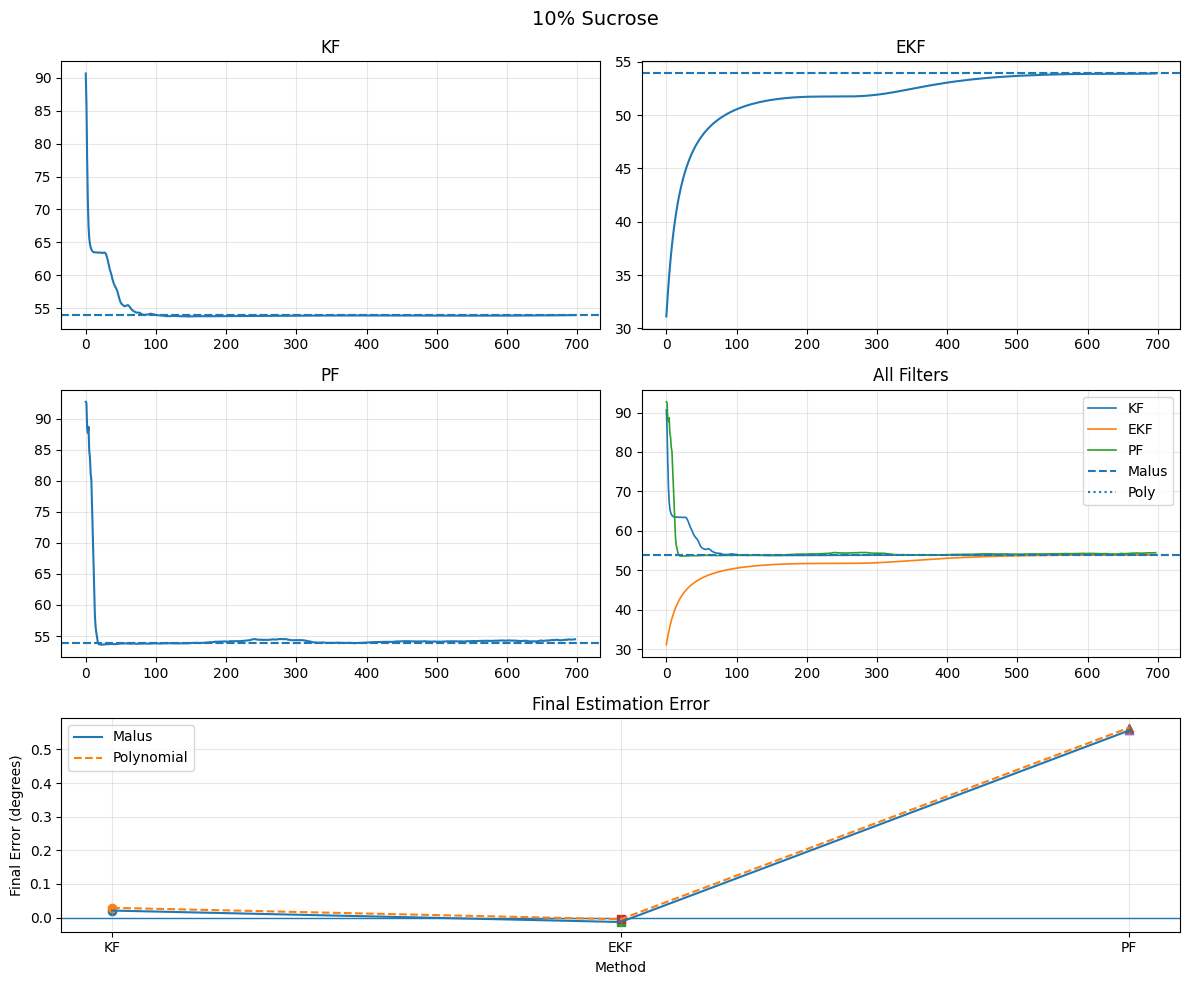

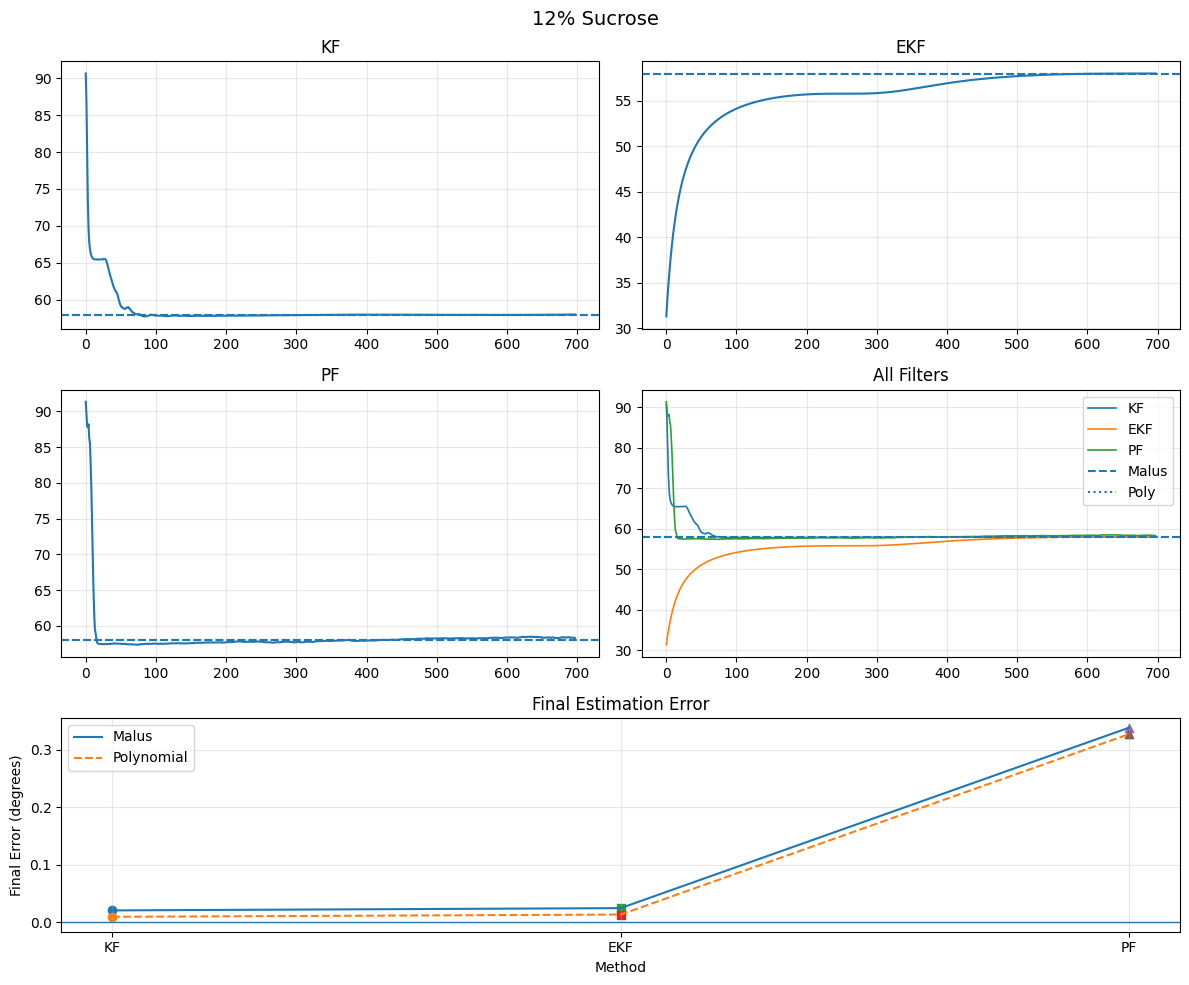

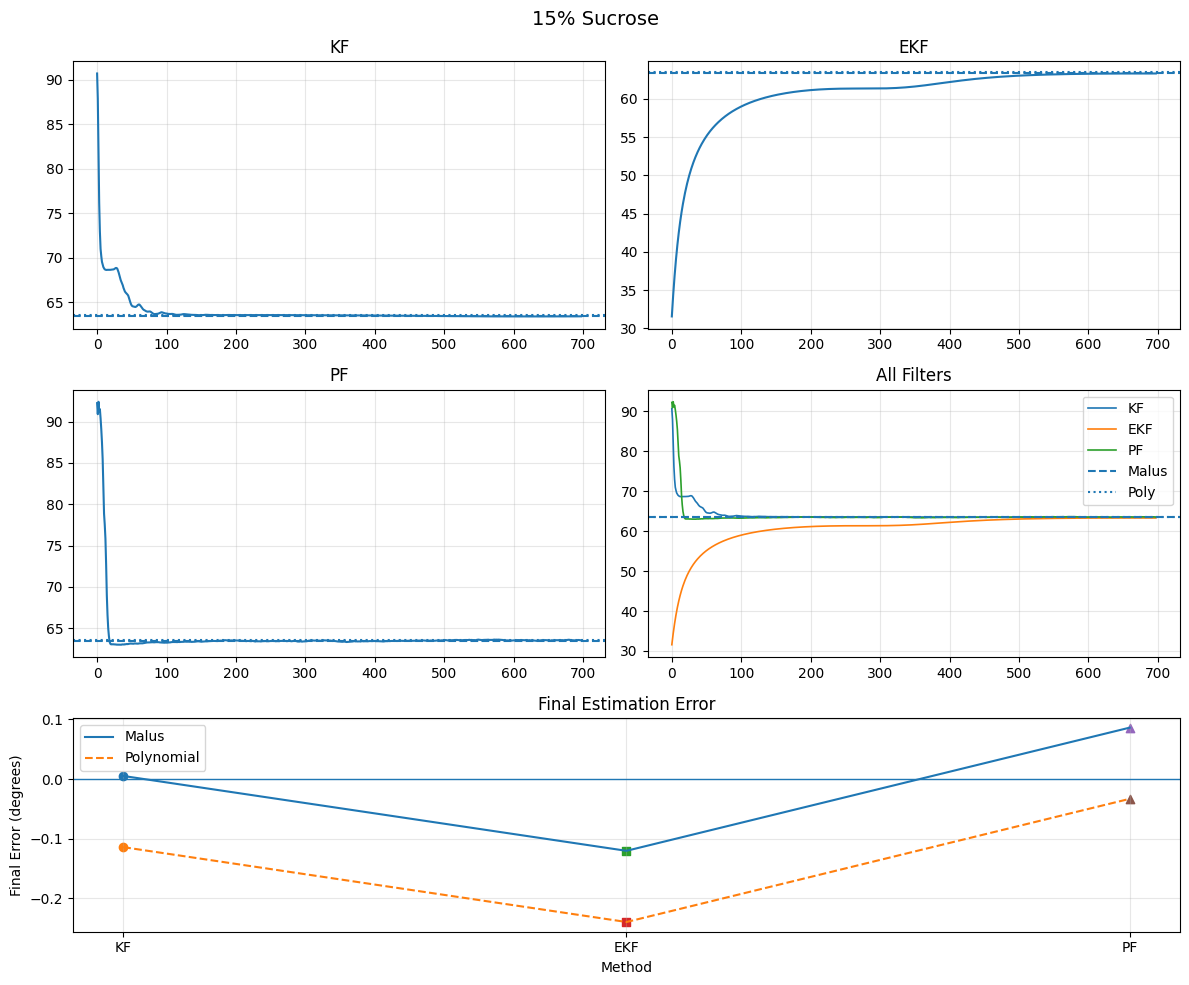

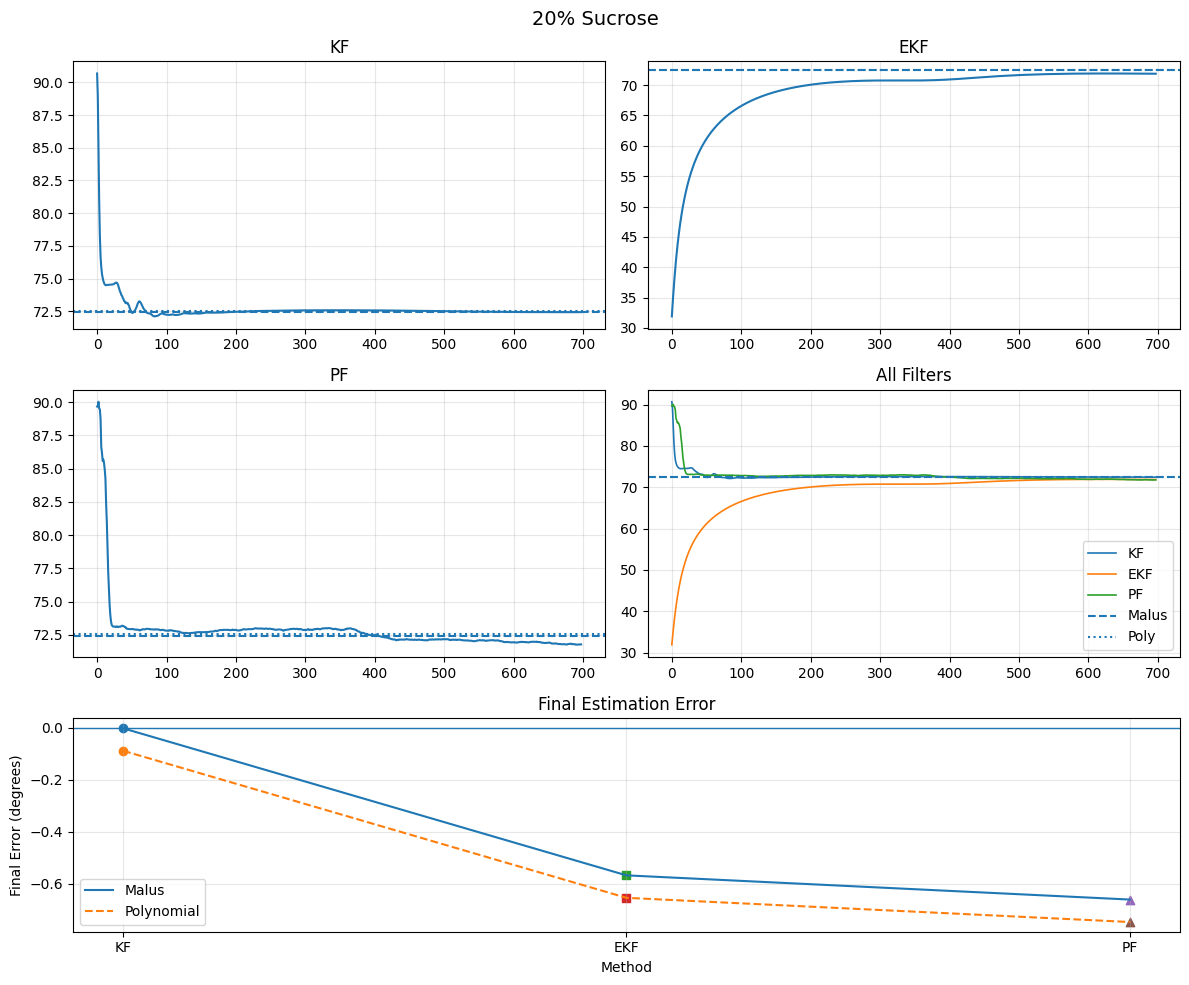

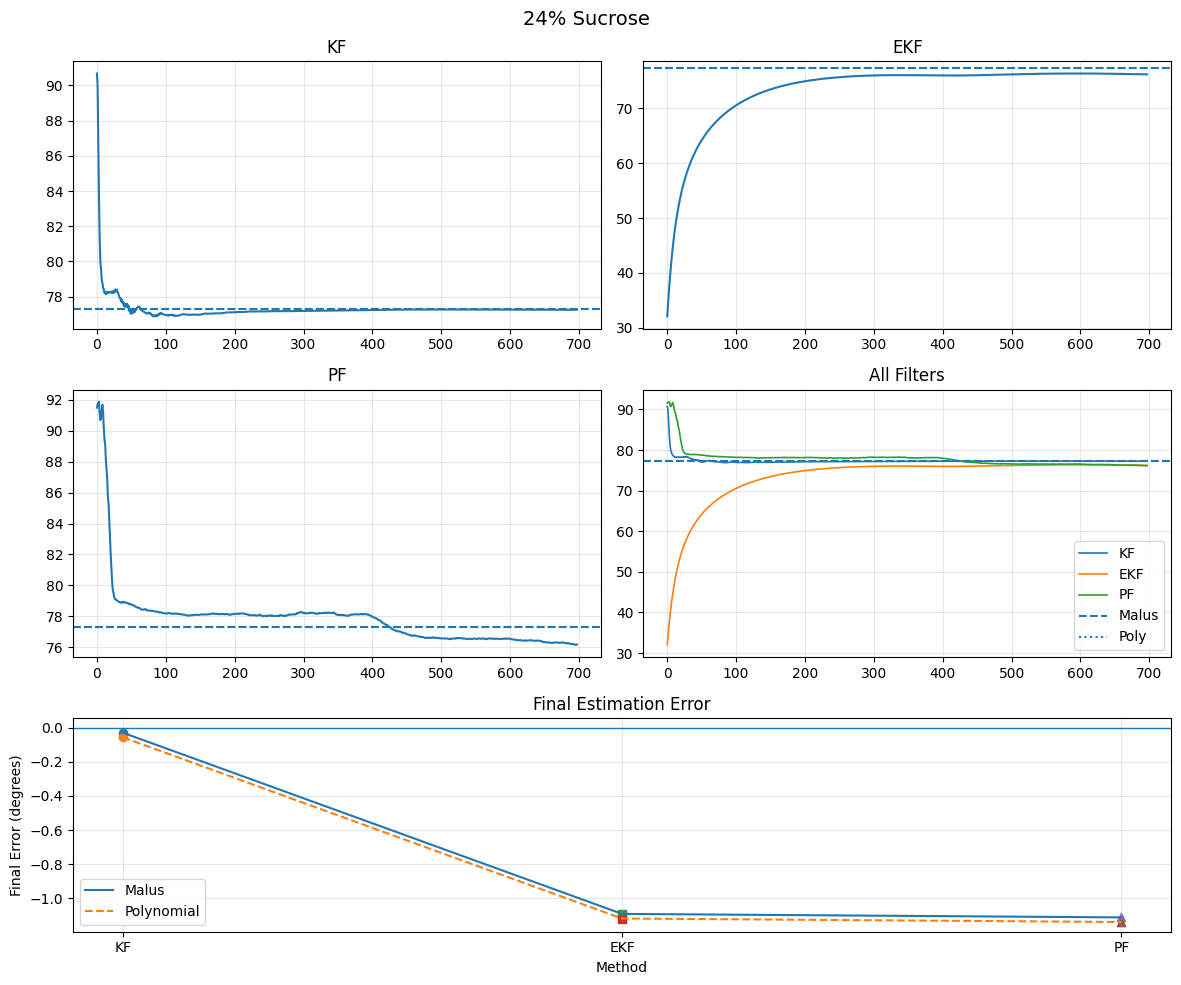

   Sucrose %  KF (Malus)  EKF (Malus)  PF (Malus)  KF (Poly)  EKF (Poly)  \
0          0      0.0324       0.0684      0.3917     0.2346      0.2706   
1          5      0.0219      -0.0155      0.2174     0.0883      0.0509   
2         10      0.0208      -0.0132      0.5563     0.0290     -0.0050   
3         12      0.0202       0.0242      0.3389     0.0090      0.0130   
4         15      0.0052      -0.1202      0.0861    -0.1140     -0.2394   
5         20     -0.0026      -0.5686     -0.6617    -0.0891     -0.6551   
6         24     -0.0295      -1.0915     -1.1120    -0.0566     -1.1185   

   PF (Poly)  
0     0.5939  
1     0.2838  
2     0.5646  
3     0.3277  
4    -0.0331  
5    -0.7482  
6    -1.1390  


In [5]:
# ============================================================
# FILTER EXECUTION AND COMPARISON
# ------------------------------------------------------------
# - Runs KF, EKF, PF on all sucrose levels
# - Visualizes convergence behavior
# - Compares against Malus and Polynomial estimates
# ============================================================

all_results = {}
all_results = {}

for sucrose in sucrose_levels:

    angles, mean_I, _ = average_curves(grouped_norm[sucrose])

    kf_est = kalman_filter(angles, mean_I)
    ekf_est = ekf(angles, mean_I)
    pf_est = particle_filter(angles, mean_I)

    all_results[sucrose] = {
        "kf": kf_est,
        "ekf": ekf_est,
        "pf": pf_est,
        "angles": angles
    }

for sucrose in sucrose_levels:

    res = all_results[sucrose]

    fig = plt.figure(figsize=(12, 10))

    # Create grid: 3 rows, 2 cols
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.8])

    ax_kf  = fig.add_subplot(gs[0, 0])
    ax_ekf = fig.add_subplot(gs[0, 1])
    ax_pf  = fig.add_subplot(gs[1, 0])
    ax_all = fig.add_subplot(gs[1, 1])
    ax_err = fig.add_subplot(gs[2, :])  # full width

    # -------------------------------
    # MAIN PLOTS
    # -------------------------------
    ax_kf.plot(res["kf"], linewidth=1.5)
    ax_kf.axhline(theta_min_results[sucrose], linestyle='--')
    ax_kf.axhline(theta_poly_results[sucrose], linestyle=':')
    ax_kf.set_title("KF")
    ax_kf.grid(alpha=0.3)

    ax_ekf.plot(res["ekf"], linewidth=1.5)
    ax_ekf.axhline(theta_min_results[sucrose], linestyle='--')
    ax_ekf.axhline(theta_poly_results[sucrose], linestyle=':')
    ax_ekf.set_title("EKF")
    ax_ekf.grid(alpha=0.3)

    ax_pf.plot(res["pf"], linewidth=1.5)
    ax_pf.axhline(theta_min_results[sucrose], linestyle='--')
    ax_pf.axhline(theta_poly_results[sucrose], linestyle=':')
    ax_pf.set_title("PF")
    ax_pf.grid(alpha=0.3)

    ax_all.plot(res["kf"], label="KF", linewidth=1.2)
    ax_all.plot(res["ekf"], label="EKF", linewidth=1.2)
    ax_all.plot(res["pf"], label="PF", linewidth=1.2)
    ax_all.axhline(theta_min_results[sucrose], linestyle='--', label="Malus")
    ax_all.axhline(theta_poly_results[sucrose], linestyle=':', label="Poly")
    ax_all.set_title("All Filters")
    ax_all.legend()
    ax_all.grid(alpha=0.3)

    # -------------------------------
    # FINAL VALUE ERROR ONLY
    # -------------------------------

    kf_final  = res["kf"][-1]
    ekf_final = res["ekf"][-1]
    pf_final  = res["pf"][-1]

    methods = ["KF", "EKF", "PF"]
    x = np.arange(len(methods))

    # Errors
    err_malus = [
        kf_final  - theta_min_results[sucrose],
        ekf_final - theta_min_results[sucrose],
        pf_final  - theta_min_results[sucrose]
    ]

    err_poly = [
        kf_final  - theta_poly_results[sucrose],
        ekf_final - theta_poly_results[sucrose],
        pf_final  - theta_poly_results[sucrose]
    ]

    # -------------------------------
    # PLOT
    # -------------------------------
    ax_err.axhline(0, linewidth=1)

    # Malus (solid line)
    ax_err.plot(x, err_malus, linestyle='-', label="Malus")

    # Poly (dashed)
    ax_err.plot(x, err_poly, linestyle='--', label="Polynomial")

    # Markers per method
    markers = ['o', 's', '^']
    for i in range(3):
        ax_err.scatter(x[i], err_malus[i], marker=markers[i])
        ax_err.scatter(x[i], err_poly[i], marker=markers[i])

    # Labels
    ax_err.set_xticks(x)
    ax_err.set_xticklabels(methods)
    ax_err.set_xlabel("Method")
    ax_err.set_ylabel("Final Error (degrees)")
    ax_err.set_title("Final Estimation Error")

    ax_err.legend()
    ax_err.grid(alpha=0.3)

    # -------------------------------
    # TITLE
    # -------------------------------
    fig.suptitle(f"{sucrose}% Sucrose", fontsize=14)

    plt.tight_layout()
    plt.show()
    
# ============================================================
# ERROR TABLE (FINAL ESTIMATION ERROR)
# ------------------------------------------------------------
# - Computes final error of KF, EKF, PF
# - Compared against:
#     1. Malus Fit (reference)
#     2. Polynomial Fit
# - Outputs a clean table using pandas
# ============================================================

import pandas as pd

rows = []

for sucrose in sucrose_levels:
    
    res = all_results[sucrose]
    
    kf_final  = res["kf"][-1]
    ekf_final = res["ekf"][-1]
    pf_final  = res["pf"][-1]
    
    row = {
        "Sucrose %": sucrose,
        
        # Errors w.r.t Malus
        "KF (Malus)":  kf_final  - theta_min_results[sucrose],
        "EKF (Malus)": ekf_final - theta_min_results[sucrose],
        "PF (Malus)":  pf_final  - theta_min_results[sucrose],
        
        # Errors w.r.t Polynomial
        "KF (Poly)":  kf_final  - theta_poly_results[sucrose],
        "EKF (Poly)": ekf_final - theta_poly_results[sucrose],
        "PF (Poly)":  pf_final  - theta_poly_results[sucrose],
    }
    
    rows.append(row)

df_errors = pd.DataFrame(rows)
print(df_errors.round(4))

## Analysis of recursive vs non-recursive methods

### Results (final estimate minus the Malus-fit theta_min, degrees)

| Sucrose % | Malus fit theta_min | Polynomial | Linear KF | EKF | PF |
|---|---|---|---|---|---|
| 0 | 37.09 | -0.20 | +0.03 | +0.07 | +0.39 |
| 5 | 45.48 | -0.07 | +0.02 | -0.02 | +0.22 |
| 10 | 53.92 | -0.01 | +0.02 | -0.01 | +0.56 |
| 12 | 57.94 | +0.01 | +0.02 | +0.02 | +0.34 |
| 15 | 63.44 | +0.12 | +0.01 | -0.12 | +0.09 |
| 20 | 72.44 | +0.09 | -0.00 | -0.57 | -0.66 |
| 24 | 77.28 | +0.03 | -0.03 | -1.09 | -1.11 |

The optical rotation grows linearly with concentration: theta_min = 1.716 x concentration + 37.14 degrees.

### Comparison

**Accuracy.** The linear Kalman filter stays within 0.035 deg of the Malus fit at every concentration. The polynomial fit is within 0.2 deg. The EKF is accurate up to 15% sucrose but drifts to -0.57 deg at 20% and -1.09 deg at 24%. It starts at 30 deg and climbs towards the answer slowly. Its covariance shrinks before it gets there, so with small process noise it settles short of the true value, and the further theta_min is from 30 deg, the larger the gap (see the 24% plot). The particle filter's errors range from 0.09 to 1.1 deg.

**Why the linear KF works so well.** Malus' law I0 sin^2(theta - theta_min), plus an offset, is exactly linear in the three unknowns a, b and c. So there is nothing to linearise, no initial guess for theta_min is needed, and the filter is effectively recursive least squares on the true model. My first version linearised sin^2 numerically around the current estimate. That made it the same algorithm as the EKF, which is why the two gave identical numbers.

**Computational demand.** The polynomial and Malus fits are batch methods: they need the whole sweep before giving an answer. The KF and EKF do a constant, small amount of work per measurement (a 3 x 3 update for the KF, a scalar update for the EKF). The PF costs O(N) per measurement, with N = 1,000 particles here.

**Implementation complexity.** The polynomial fit is the simplest (np.polyfit around the minimum), but depends on choosing the window. The linear KF needs the trigonometric rewrite but no Jacobian and no tuning of an initial angle. The EKF needs the Jacobian and a reasonable initial guess. The PF needs an initial particle spread, a likelihood width, resampling and roughening. With 200 particles and 0.5 deg roughening (my first settings) its errors reached 3 deg. With 1,000 particles and 0.05 deg they are below 1.2 deg.

**Real-time use.** All three recursive filters update as each angle arrives, so they can report theta_min during the sweep. The batch fits cannot.

### Best overall method

The **linear Kalman filter**: the most accurate here, cheap, real-time and independent of the initial guess. The polynomial fit is a good offline check. The EKF is fine when it starts close to the answer. The particle filter is only worth its cost when the noise is clearly non-Gaussian or the posterior has several modes, for example if the sweep covered more than 180 deg and several minima were possible.

### Sources of error

Sensor noise, imperfect rotation and misalignment of the analyser, ambient light, light-source drift, and the angular step limiting resolution near the minimum (as discussed in Part 1). The spread across trials is largest at 24% sucrose, which matches where every method's estimates spread the most.